In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import pandas as pd
from numpy import pi
from scipy import optimize
import bateman as bt
import thermalization as th
import heat_alpha as ht
import lightcurve as lc

from astropy import units as u
from astropy import constants as const
c = const.c.cgs.value
day = 86400.
Msun = const.M_sun.cgs.value

%matplotlib inline
%load_ext autoreload
%autoreload 2

### - Read effective opacities to gamma-rays for each element

In [2]:
fkappa = pd.read_csv('input_files/effective_kappa_A85_238.dat', sep=r'\s+', header=None)
kappa_effs = 0.02*np.ones((240,100))
for i in range(0,len(fkappa)):
    A = fkappa[0][i]
    Z = fkappa[1][i]
    kappa = np.sqrt(fkappa[3][i]*fkappa[4][i])
    kappa_effs[A][Z] = kappa

### - Read abundances of each beta-decay chain 

The file format is $(Z, A, Y)$, where $Z$ is an atomic number, $A$ is an atomic mass number, and $Y$ is a number fraction. The following example file corresponds to the solar r-process pattern with $A \geq 70$. (beta-decay chains between $A=50$ and $209$ can be included.)

In [3]:
ffraction = pd.read_csv('input_files/solar_r_abundance_pattern.dat', sep=r'\s+', header=None)

### - Define the range of atomic numbers of beta-decay chains and the ejecta model (density profile). 

We use a radial density profile of merger ejecta with a total mass of $M_{\rm ej}$ and a minimum velocity of $v_0$:

$$
\begin{align}
\rho(t,v) = \rho_0(t)\left(\frac{v_{\rm ej}}{v_0}\right)^{-n}~{\rm for}~(v_0\leq v_{\rm ej}\leq v_{\rm max})
\end{align}
$$

where $\rho_0(t)$ is defined such that:

$$
\begin{align}
M_{\rm ej} = 4\pi \int_{v_0}^{v_{\rm max}}dvv^2 \rho(t,v).
\end{align}
$$

In [4]:
##########Start input parameters
Amin = 88
Amax = 209

##########ejecta parameters for thermalization
Mej = 0.023*Msun
vej = 0.1*c
n = 4.5
alpha_max = 4.0#v_max = alpha_max * vej
alpha_min = 1.#v_min = alpha_min * vej

### - Input abundances (number fraction) of each alpha-decay chain. 

`Yas[A]` = number abundance of alpha decay chain starting with $A$ (can be from $209$ to $238$). The following example is taken from Wu et al. (2018).

In [5]:
Yas = np.zeros(239)
Yas[222] = 4.0e-5
Yas[223] = 2.7e-5
Yas[224] = 4.1e-5
Yas[225] = 2.7e-5

### - Calculate the beta-decay radioactive power and heating rate

In [6]:
beta = ht.calc_heating_rate(Mej,vej, Amin,Amax,ffraction,kappa_effs,alpha_max,alpha_min,n)

### - Calculate the beta-decay radioactive power and heating rate

In [7]:
alpha = ht.calc_heating_rate_alpha(Mej,vej, Amin,Amax,ffraction,Yas,kappa_effs,alpha_max,alpha_min,n)

### - Write the data to a file

$t~[{\rm day}]$, heating rates: $[{\rm erg/s/g}]$

In [8]:
data = {'t':beta['t'],'total':beta['total'],'gamma':beta['gamma'], 'electron':beta['electron'], 'gamma_th':beta['gamma_th'],'electron_th':beta['electron_th']}
df = pd.DataFrame(data=data)
df.to_csv('output_files/heat_beta_88_209_M005_v04_v1_n45.dat',sep=" ",index=False,header=None,columns=['t', 'total', 'gamma', 'electron','gamma_th','electron_th'])

In [9]:
data = {'t':alpha['t'],'total':alpha['total'],'alpha':alpha['alpha'],'gamma':alpha['gamma'], 'electron':alpha['electron'],'alpha_th':alpha['alpha_th'], 'gamma_th':alpha['gamma_th'],'electron_th':alpha['electron_th']}
df = pd.DataFrame(data=data)
df.to_csv('output_files/heat_alpha_Wu19_88_209_M005_v04_v1_n45.dat',sep=" ",index=False,header=None,columns=['t', 'total', 'alpha', 'gamma', 'electron','alpha_th','gamma_th','electron_th'])

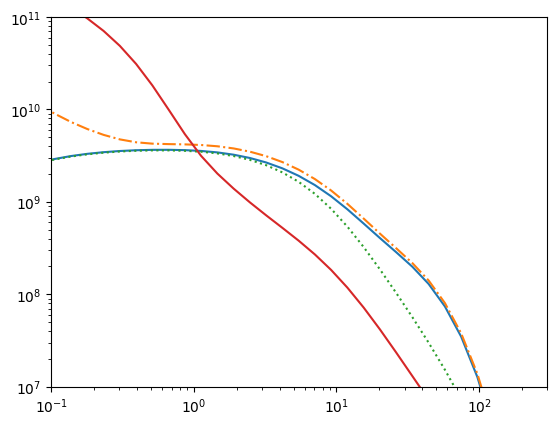

In [10]:
plt.ylim(1.0e7,1.0e11)
plt.xlim(0.1,300.)
plt.loglog(alpha['t'],np.multiply(alpha['alpha'],1.))
plt.loglog(alpha['t'],np.multiply(alpha['total'],1.),linestyle='-.')
plt.loglog(alpha['t'],np.multiply(alpha['alpha_th'],1.),linestyle=':')
plt.loglog(beta['t'],np.multiply(beta['electron_th'],1.),linestyle='-')
plt.savefig('output_files/heat.pdf')
plt.show()

### - Bolometric light curve and temperature at the photosphere

The opacities of the inner and outer parts of the ejecta are set to be:

$$
\begin{align}
\kappa=\kappa_{\rm high}~{\rm for}~(v\leq v_{\kappa})~~~~{\rm and}~~~~\kappa=\kappa_{\rm low}~{\rm for}~(v>v_{\kappa})
\end{align}
$$

In [11]:
#input parameters for the calculation of a light curve
kappa_low = 0.5  #opacity [cm^2/g] for v > v_kappa
kappa_high = 3.0 #opacity [cm^2/g] for v < v_kappa
be_kappa = 0.14

heat_time = np.array(beta['t'])
heat_rate = np.array(beta['electron_th'])+np.array(beta['gamma_th'])+np.array(alpha['alpha_th'])+np.array(alpha['electron_th'])+np.array(alpha['gamma_th'])

### - Compute the bolometric light curve and temperature at the photosphere

In [12]:
LCdata = lc.calc_lightcurve(Mej,vej,alpha_max,alpha_min,n,kappa_low,kappa_high,be_kappa,heat_time, heat_rate)
LC = {'t':LCdata['t']*u.s,'LC':LCdata['LC']*u.erg/u.s,'Temp':LCdata['T']*u.K}

4.630669927265643e+31 0.40000000000000024 200


### - Write the data to a file

$t~[{\rm day}]$, light curve: $[{\rm erg/s}]$, temperature: $[{\rm K}]$

In [13]:
data = {'t':LC['t'],'LC':LC['LC'],'Temp':LC['Temp']}
df = pd.DataFrame(data=data)
df.to_csv('output_files/lightcurve.dat',sep=" ",index=False,header=None,columns=['t', 'LC', 'Temp'])

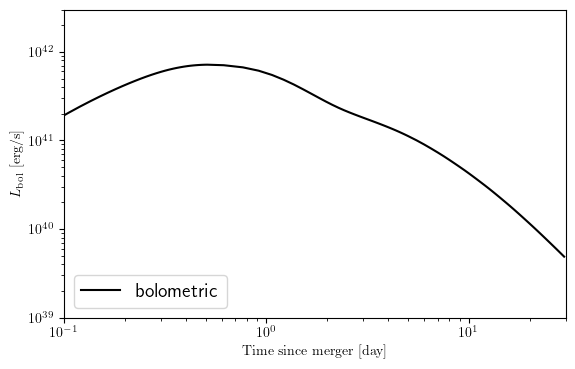

In [14]:
from matplotlib import rc
rc('text', usetex=True)
fig, ax = plt.subplots(figsize=(6.472135955, 4))
plt.xlim(0.1,30.)
plt.ylim(1.0e39,3.0e42)
plt.ylabel(r"$L_{\rm bol}~[{\rm erg/s}]$")
plt.xlabel(r"${\rm Time~since~merger~[day]}$")
plt.loglog(LC['t'].to(u.d),LC['LC'],label='bolometric',linestyle='-',linewidth=1.5,color='k')

#plt.text(30,1.0e11,'$88\leq A\leq 209$',fontsize=13.5)

plt.legend(loc='lower left',fontsize=14)
plt.savefig("output_files/LC_A85.pdf",dpi=600,bbox_inches='tight')
plt.show()